# Regime switching on its own: HMM-gated experts

**The question:** does regime switching help when it is tested on its own, with no link to the
linear model or the hybrid?

**The model** (`models.regime_switching`, `docs/regime_switching.md`):

    forecast(k) = Σ_s g_s × expert_s(k)

- **g_s:** P(state s at t0 | in-situ data up to t0), the forward filter of a K-state hidden Markov model (`models.regime_hmm`, level emissions on speed, log temperature ratio and log Bt) at the in-situ row labelled t0 − 1h. It is causal, so it would be known live.
- **expert_s:** a per-lead weighted ridge regression of v(t0+k) − last speed. Each expert is fitted on every training run, with weight = TIMSE weight × g_s(t0).
- **Two input sets for the experts:**
  - **speed:** the last speed and the 27-day and 13.5-day recurrence means at t0+k;
  - **regs:** the same plus the 4 regressors the linear model selected, used as inputs only.
- **Gating:** soft (the mixture above) or hard (the most probable state's expert).
- **The control is K = 1:** one state, gate = 1, a single global regression with the same inputs. The gain of K > 1 over K = 1 is what regime switching adds.
- **"hmm alone":** the 4-state Markov-switching AR HMM's own multi-step forecast, with no experts.

**Setup** (`python -m training.regime_switching`):
- **Folds:** the six yearly walk-forward folds (2019-10 → 2025-10). Per fold, the HMM and the experts are fitted on the data before the fold start.
- **Score:** per-run mean TIMSE relative to persistence; the summary is the geometric mean over folds.
- **Context:** the final baseline, the shipped linear model and the hybrid on the same folds, from earlier runs.
- **The eval year is not used.**

**Decision rule (set before running):** regime switching helps on its own if the best K > 1 beats
K = 1 with the same inputs by more than 2% and wins at least 4 of 6 folds.

1. Fold scores
2. Gain over K = 1, by K and fold
3. What the regimes are (K = 4) and what each expert learned
4. Where the gain comes from (2024 fold)
5. Findings

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from feature_engineering.recurrence import HORIZON
from models.regime_switching import Config, RegimeSwitchingModel
from training import linear_model as tl
from training import regime_models as rm
from training import regime_switching as rs
from training.datasets import DATA_START

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.width", 200)
scores = pd.read_csv(rs.EXPERIMENTS / "regime_switching.csv").set_index("fold")
cached = {p.stem: json.loads(p.read_text(encoding="utf-8"))
          for p in sorted(rs.CACHE_DIR.glob("*.json"))}
cols = [c for c in scores.columns if c != "seconds"]


def geo(s):
    return float(np.exp(np.log(s.dropna()).mean()))


def fmt(df, digits=4):
    return df.style.format(precision=digits)


print(f"{len(scores)} folds: {', '.join(scores.index)}")

6 folds: 2019-10, 2020-10, 2021-10, 2022-10, 2023-10, 2024-10


## 1. Fold scores

In [2]:
rows = {}
for c in cols:
    inputs = c.split()[-1] if c.startswith("K=") else None
    control = f"K=1 soft {inputs}" if inputs else None
    rows[c] = {"fold score": geo(scores[c]),
               "vs K=1 (same inputs)": geo(scores[c]) / geo(scores[control]) - 1
               if control else np.nan,
               "folds won vs K=1": int((scores[c] < scores[control]).sum()) if control
               else np.nan,
               "vs linear": geo(scores[c]) / geo(scores["linear"]) - 1}
summary = pd.DataFrame(rows).T.sort_values("fold score")
display(summary.style.format({"fold score": "{:.4f}", "vs K=1 (same inputs)": "{:+.1%}",
                              "folds won vs K=1": "{:.0f}", "vs linear": "{:+.1%}"},
                             na_rep=""))

,fold score,vs K=1 (same inputs),folds won vs K=1,vs linear
hybrid,0.4258,,,-2.9%
K=1 soft regs,0.4375,+0.0%,0,-0.3%
linear,0.4387,,,+0.0%
K=2 soft regs,0.4396,+0.5%,1,+0.2%
K=2 hard regs,0.4401,+0.6%,1,+0.3%
K=3 soft regs,0.4421,+1.1%,1,+0.8%
K=3 hard regs,0.4429,+1.2%,1,+0.9%
K=4 soft regs,0.4474,+2.3%,0,+2.0%
K=5 soft regs,0.4489,+2.6%,1,+2.3%
K=4 hard regs,0.4490,+2.6%,0,+2.3%


## 2. Gain over K = 1, by K and fold

Change in fold score against K = 1 with the same inputs (soft gating). Below 0, regime switching
helps.

,speed,regs
K,,
2,+0.14%,+0.12%
3,+0.06%,+0.17%
4,+0.55%,+0.35%
5,+0.14%,+0.24%


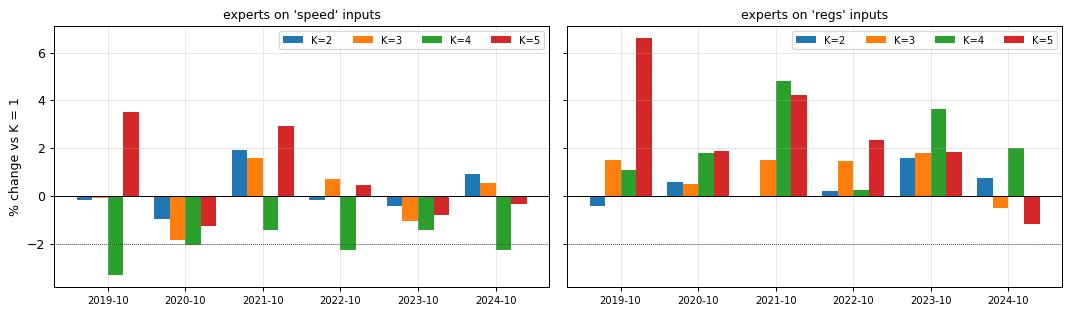

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
x = np.arange(len(scores))
for ax, inputs in zip(axes, ["speed", "regs"], strict=True):
    for i, k in enumerate(range(2, 6)):
        c = f"K={k} soft {inputs}"
        ax.bar(x + (i - 1.5) * 0.2, 100 * (scores[c] / scores[f"K=1 soft {inputs}"] - 1), 0.2,
               label=f"K={k}")
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(-2, color="k", lw=0.6, ls=":")
    ax.set_xticks(x, scores.index, fontsize=8)
    ax.set_title(f"experts on '{inputs}' inputs", fontsize=10)
    ax.legend(fontsize=8, ncol=4)
axes[0].set_ylabel("% change vs K = 1")
fig.tight_layout()

soft_hard = pd.DataFrame({
    inputs: {k: geo(scores[f"K={k} hard {inputs}"]) / geo(scores[f"K={k} soft {inputs}"]) - 1
             for k in range(2, 6)} for inputs in ("speed", "regs")})
soft_hard.index.name = "K"
display(soft_hard.style.format("{:+.2%}").set_caption("hard vs soft gating (fold score)"))

## 3. What the regimes are (K = 4) and what each expert learned

The 4-state HMM and its experts, refitted on the hours before the 2024 fold. The HMM table gives
each state's mean speed, temperature ratio and field, its mean stay, and its share of time. The
expert plots show each state's coefficients by lead (speed inputs):
- the weight on the last speed (persistence);
- the weight on the 27-day recurrence mean;
- the intercept (km/s, at mean inputs).

,speed mean,speed sd,T ratio,Bt (nT),mean stay (h),stationary share
slow,333.68,24.68,1.08,3.82,54.49,0.31
intermediate,398.31,40.26,1.15,8.10,22.98,0.20
fast,550.91,66.97,1.07,5.33,50.87,0.23
ejecta,415.55,29.69,1.03,3.93,33.19,0.25


share of the 2024 fold's runs by most probable state: {'slow': 0.078, 'intermediate': 0.377, 'fast': 0.421, 'ejecta': 0.124}


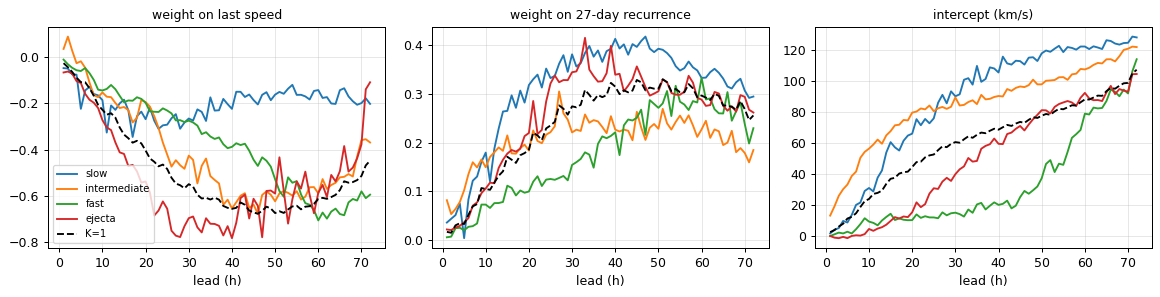

In [4]:
data = rs.Data()
start, end = pd.Timestamp("2024-10-20T00:00Z"), pd.Timestamp("2025-10-20T00:00Z")
fold = data.fold(start, end)
start_pos = data.series.index.get_loc(start)
fit6 = data.runs6[(data.runs6 >= DATA_START) & (data.runs6 < start)]
fit_pos = data.series.index.get_indexer(fit6)
before = data.insitu[data.insitu.index < start]
models, gates = {}, {}
for k in (1, 4):
    base = RegimeSwitchingModel(Config(n_states=k)).fit_hmm(before)
    gates[k] = (base.gate(data.insitu, fit6), base.gate(data.insitu, fold["t0s"]))
    for inputs, feats in data.input_sets.items():
        m = RegimeSwitchingModel(Config(n_states=k, features=feats), base.hmm)
        models[(k, inputs)] = m.fit(data.values, fit_pos, gates[k][0], data.x(fit6, feats),
                                    end=start_pos)
hmm4 = models[(4, "speed")].hmm
display(fmt(hmm4.summary()[["speed mean", "speed sd", "T ratio", "Bt (nT)", "mean stay (h)",
                            "stationary share"]], 2))
print("share of the 2024 fold's runs by most probable state:",
      dict(zip(hmm4.names, (np.bincount(gates[4][1].argmax(axis=1), minlength=4)
                            / len(gates[4][1])).round(3).tolist(), strict=True)))

coef = models[(4, "speed")].coef  # (state, lead, [intercept, last, rec27, rec13])
glob = models[(1, "speed")].coef[0]
lead = np.arange(1, HORIZON + 1)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, j, title in zip(axes, [1, 2, 0], ["weight on last speed", "weight on 27-day recurrence",
                                          "intercept (km/s)"], strict=True):
    for s, name in enumerate(hmm4.names):
        ax.plot(lead, coef[s, :, j], label=name)
    ax.plot(lead, glob[:, j], color="k", ls="--", label="K=1")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("lead (h)")
axes[0].legend(fontsize=8)
fig.tight_layout()

**The gate along the 2024 fold** (first three months): the speed, with the gate's probabilities
below.

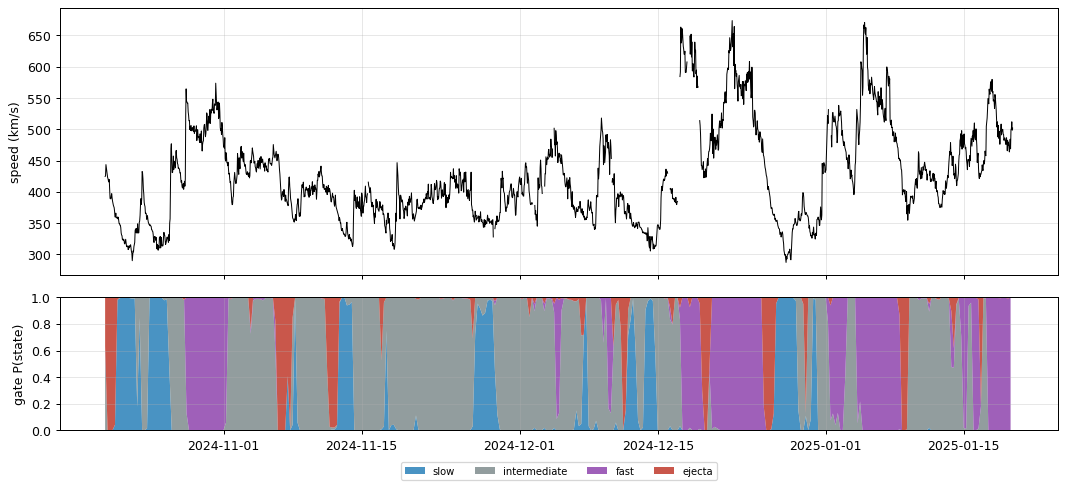

In [5]:
colors = ["#2980b9", "#7f8c8d", "#8e44ad", "#c0392b"]
t0s = fold["t0s"]
win = t0s < start + pd.Timedelta(days=92)
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
sp = data.series[(data.series.index >= start) & (data.series.index < start + pd.Timedelta(days=92))]
axes[0].plot(sp.index, sp, color="k", lw=0.8)
axes[0].set_ylabel("speed (km/s)")
axes[1].stackplot(t0s[win], gates[4][1][win].T, colors=colors, labels=hmm4.names, alpha=0.85)
axes[1].set_ylabel("gate P(state)")
axes[1].set_ylim(0, 1)
axes[1].legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2))
fig.tight_layout()

## 4. Where the gain comes from (2024 fold)

Pooled TIMSE of the K = 4 soft model against K = 1 with the same inputs, by the run's true regime
(labels from `training.regime_models`, which use the future target window; a diagnostic only)
and by the gate's most probable state.

In [6]:
labels = pd.read_pickle(rm.CACHE_DIR / "labels.pkl")
ok = fold["scored"]
route = labels.loc[fold["t0s"], "route"].to_numpy()[ok]
state = np.asarray(hmm4.names)[gates[4][1].argmax(axis=1)][ok]
tables = {}
for inputs, feats in data.input_sets.items():
    xv = data.x(fold["t0s"], feats)
    s1 = tl.run_scores(models[(1, inputs)].forecast(data.values, fold["pos"], gates[1][1], xv),
                       fold["y"], fold["q"])[ok]
    s4 = tl.run_scores(models[(4, inputs)].forecast(data.values, fold["pos"], gates[4][1], xv),
                       fold["y"], fold["q"])[ok]
    for by_name, by in (("true regime", route), ("gate state", state)):
        g = pd.DataFrame({"k4": s4, "k1": s1, "by": by}).groupby("by")
        tables[(inputs, by_name)] = (g["k4"].sum() / g["k1"].sum()).rename("K=4 / K=1")
for key, t in tables.items():
    print(f"\n{key[0]} inputs, by {key[1]}:")
    display(t.to_frame().T.style.format("{:.3f}"))


speed inputs, by true regime:


by,CME,fast stream,intermediate,slow wind,stream arrival
K=4 / K=1,1.026,1.096,0.933,1.145,0.915



speed inputs, by gate state:


by,ejecta,fast,intermediate,slow
K=4 / K=1,0.987,1.049,0.921,0.990



regs inputs, by true regime:


by,CME,fast stream,intermediate,slow wind,stream arrival
K=4 / K=1,1.082,1.068,0.856,1.047,1.025



regs inputs, by gate state:


by,ejecta,fast,intermediate,slow
K=4 / K=1,0.986,1.005,1.049,0.986


**Why the regressors absorb the gain.** The correlation, over the 2024 fold's runs, between each
state's gate probability and the 4 regressors and the last speed. The gate reads the same recent
in-situ conditions the regressors summarise.

In [7]:
from feature_engineering.recurrence import last_observed

reg = pd.DataFrame(data.x(fold["t0s"], data.input_sets["regs"]),
                   columns=list(data.input_sets["regs"]))
reg["last speed"] = last_observed(data.values, fold["pos"])
gate = pd.DataFrame(gates[4][1], columns=[f"P({n})" for n in hmm4.names])
display(fmt(pd.concat([gate, reg], axis=1).corr().loc[gate.columns, reg.columns], 2)
        .background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))

,bt_mean_1h,ch_cm_at_24h,xray_peak_max_72h,density_mean_24h,last speed
P(slow),-0.19,-0.05,0.13,-0.00,-0.41
P(intermediate),0.42,-0.06,0.02,0.38,-0.46
P(fast),-0.08,0.12,-0.09,-0.28,0.79
P(ejecta),-0.35,-0.05,0.00,-0.13,-0.21


## 5. Findings

### Verdict: regime switching only helps experts that lack the regressors; not built

| Six folds | Fold score | vs K = 1, same inputs | Folds won vs K = 1 |
|---|---|---|---|
| hybrid (shipped, context) | 0.4258 | | |
| **K = 1, speed + regressors** | **0.4375** | | |
| linear (shipped, context) | 0.4387 | | |
| K = 2, speed + regressors | 0.4396 | +0.5% | 1 |
| K = 4, speed + regressors | 0.4474 | +2.3% | 0 |
| **K = 4, speed only** | **0.4836** | **−2.1%** | **6** |
| final baseline (context) | 0.4843 | | |
| K = 1, speed only | 0.4941 | | |
| HMM alone (its own forecast) | 0.7910 | | |

- **Speed-only experts:** K = 4 passes the decision rule, just: −2.1% against K = 1, in all 6 folds. K = 2, 3 and 5 don't help, so the gain belongs to the 4-state HMM (initialised with an ejecta state), not to regime switching in general. Even then it only reaches the final baseline's level.
- **Speed + regressors:** every K > 1 is worse than K = 1 (+0.5% to +2.8%). The best standalone model is the single regression, K = 1, which is 0.3% better than the shipped linear model. That is unrelated to regimes.
- **Soft vs hard gating** makes little difference (hard is 0.1–0.5% worse).
- **The HMM alone** (its own multi-step forecast) scores 0.79, close to persistence. Without the 27-day recurrence it can only relax toward each state's level.

### (i) What the K = 4 gate captures

- **The states,** fitted before 2024-10:
  - slow, 334 km/s;
  - fast, 551 km/s;
  - "intermediate", 398 km/s with a strong field (8.1 nT) and high temperature ratio. This is compressed plasma, typical of the interaction region ahead of a fast stream;
  - "ejecta", 416 km/s, which is just another intermediate state, not cold.
- **Where the gain comes from,** speed-only experts on the 2024 fold, pooled TIMSE against K = 1:
  - by the gate's state: 0.92 on runs gated "intermediate";
  - by true regime: 0.92 on stream arrivals and 0.93 on intermediate wind;
  - the costs: fast streams 1.10 and slow wind 1.15.
- **What the experts learned:** the "intermediate" state's expert raises its forecast with the lead, anticipating the stream behind the compression.

### (ii) Why the regressors absorb it

The gate reads the same recent in-situ conditions that the regressors summarise. On the 2024 fold,
P(intermediate) correlates 0.42 with `bt_mean_1h` and 0.38 with `density_mean_24h`, and P(fast)
correlates 0.79 with the last speed. Once those inputs are in every expert, splitting the training
runs four ways only adds variance: each expert sees a quarter of the data. That is why K > 1 gets
worse as K grows.

### What this means

1. **Regime switching is not built.** Its only gain comes from information that a single regression already gets from the regressors.
2. **This agrees with the earlier studies:**
   - routing (`regime_models.ipynb`): regimes can't be predicted at t0;
   - HMM features (`regime_hmm.ipynb`): HMM states are redundant with the hybrid's inputs.

   The present-state regime is already well described by the regressors, and the future regime is what the inputs can't foresee.
3. **A side result:** the K = 1 expert with the linear model's 4 regressors (0.4375) is level with the shipped linear model (0.4387). Its per-lead ridge on the speed difference is a simpler fit than the linear model's GLM, and it gives the same score.

### Caveats

- **Experts are linear;** nonlinear experts were not tried. The hybrid's trees already split on the same inputs.
- **The HMM uses level emissions on 3 in-situ signals;** other emission sets were not tried.
- **The 4-state HMM starts from physical thresholds, the others from speed quantiles,** which may explain why only K = 4 helps the speed-only experts.
- **The eval year was not used.**